# Step 1: Data Exploration and Filtering

**Objective:** Load the raw SDSS DR19 Astra table, apply the five catalogue-level cuts, verify data integrity, and export the catalogue together with the label-noise floor used downstream.

The waterfall of Section 1.2 gives the sample sizes quoted in the data section of the paper, and Section 1.4 computes the label-noise floor of 47.9 K.

## 1.1 Importing Libraries and Loading the Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style for publication-ready plots
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12, 'font.family': 'serif', 'font.serif': ['Times New Roman'], 'mathtext.fontset': 'stix'})

# Define file path
file_path = 'data/sdss_all_star.csv'

# Load the raw dataset
print("Loading dataset...")
raw_df = pd.read_csv(file_path, low_memory=False)

# Display initial statistics
print("-" * 40)
print(f"Total raw spectra loaded: {len(raw_df):,}")
print("Columns available:", raw_df.columns.tolist())
print("-" * 40)

# Display the first few rows to verify data types
display(raw_df.head(3))

Loading dataset...
----------------------------------------
Total raw spectra loaded: 1,365,542
Columns available: ['catalogid', 'sdss_id', 'pipeline', 'spectral_type', 'sub_type', 'classification', 'teff', 'e_teff', 'logg', 'e_logg', 'snr', 'v_rad', 'e_v_rad']
----------------------------------------


,catalogid,sdss_id,pipeline,spectral_type,sub_type,classification,teff,e_teff,logg,e_logg,snr,v_rad,e_v_rad
0,27021599488832507,66920479,apogee_net,NaN,-9999,NaN,21141.240,939.40030,3.808637,0.040067,424.423130,57.424145,0.000000
1,27021598854854726,89857096,boss_net,NaN,-9999,NaN,8768.460,954.90283,3.369935,0.138719,62.375813,29.636152,6.651578
2,27021598666247530,86953037,boss_net,NaN,-9999,NaN,12584.387,1173.04420,3.808222,0.068288,85.605090,40.121853,6.397947


## 1.2 Applying Core Physical Boundaries

Cuts are applied **sequentially** so that the contribution of each criterion can be audited (waterfall table below).

- **Pipeline:** must contain `boss_net` (covers `boss_net` and `boss_net|slam`). These are the only optical pipelines in Astra, hence the only ones compatible with the BOSS spectra used as model input.
- **SNR > 25.** Stricter than the SDSS default of 10-15, so that weak absorption lines remain separable from the noise floor. This matters here because the study applies controlled artefacts later: the clean baseline must itself be clean.
- **3.5 <= log g <= 5.5.** Isolates main-sequence dwarfs. Giants and dwarfs of the same Teff differ in line profile through pressure broadening, so mixing luminosity classes introduces a Teff-log g degeneracy the model would have to absorb.
- **3500 <= Teff <= 9000 K.** The lower bound is set by the coolest M dwarfs present. The upper bound truncates a sparse hot tail: above 9000 K the sample density collapses below ~50 stars per 250 K bin, which is not learnable, while the density-based label weighting used in training would grant those few stars an outsized share of the gradient (see the diagnostic cell for the measurement).

In [2]:
# --- Filter constants (single source of truth) -------------------------------
PIPELINE_KEY = 'boss_net'
SNR_MIN = 25
LOGG_MIN, LOGG_MAX = 3.5, 5.5
TEFF_MIN, TEFF_MAX = 3500, 9000
E_TEFF_MAX = 100

print("Applying core physical boundaries...\n")

# --- Sequential cuts, recording the survivor count at each stage --------------
stages = [("Raw Astra query (zwarning_flags=0 applied in SQL)", len(raw_df))]
df_cur = raw_df

df_cur = df_cur[df_cur['pipeline'].str.contains(PIPELINE_KEY, na=False)]
stages.append((f"Pipeline contains '{PIPELINE_KEY}'", len(df_cur)))

df_cur = df_cur[df_cur['snr'] > SNR_MIN]
stages.append((f"SNR > {SNR_MIN}", len(df_cur)))

df_cur = df_cur[(df_cur['logg'] >= LOGG_MIN) & (df_cur['logg'] <= LOGG_MAX)]
stages.append((f"{LOGG_MIN} <= log g <= {LOGG_MAX}", len(df_cur)))

# Snapshot before the Teff cut: needed as evidence for the upper-bound choice
pre_teff_df = df_cur[df_cur['teff'] >= TEFF_MIN].copy()

df_cur = df_cur[(df_cur['teff'] >= TEFF_MIN) & (df_cur['teff'] <= TEFF_MAX)]
stages.append((f"{TEFF_MIN} <= Teff <= {TEFF_MAX} K", len(df_cur)))

base_filtered_df = df_cur.copy()

# --- Waterfall table ---------------------------------------------------------
wf = pd.DataFrame(stages, columns=['Filter stage', 'Surviving'])
wf['Removed'] = (wf['Surviving'].shift(1) - wf['Surviving']).fillna(0).astype(int)
wf['% of raw'] = (100 * wf['Surviving'] / len(raw_df)).round(2)
print("Filtering waterfall:")
display(wf)

display(base_filtered_df[['teff', 'logg', 'snr']].describe().T)

Applying core physical boundaries...

Filtering waterfall:


,Filter stage,Surviving,Removed,% of raw
0,Raw Astra query (zwarning_flags=0 applied in SQL),1365542,0,100.00
1,Pipeline contains 'boss_net',359685,1005857,26.34
2,SNR > 25,259245,100440,18.98
3,3.5 <= log g <= 5.5,221520,37725,16.22
4,3500 <= Teff <= 9000 K,207577,13943,15.20


,count,mean,std,min,25%,50%,75%,max
teff,207577.0,5698.793140,1053.199348,3500.015900,4980.492700,5786.689500,6201.295000,8999.283000
logg,207577.0,4.338546,0.263846,3.500060,4.213437,4.375878,4.516712,5.499695
snr,207577.0,54.618489,39.105003,25.000004,34.181650,42.689810,56.800926,883.943900


## 1.3 Data Integrity Diagnostics

Three checks that guard against failure modes which would silently invalidate the downstream experiments.

1. **Repeat visits / data leakage.** SDSS-V observes many targets more than once. If the same star appeared in both the train and test split, the test RMSE would be optimistically biased.
2. **Pipeline segregation.** Astra selects a best-fit pipeline per source, so the label scale is not guaranteed to be homogeneous across the Teff range.
3. **Hot-tail gradient share.** Quantifies the motivation for the 9000 K cut under the density-based (LDS) label weighting used during training.


In [3]:
from scipy.ndimage import gaussian_filter1d

df = base_filtered_df

# --- 1. Repeat visits / leakage ----------------------------------------------
print("=" * 62)
print("1. REPEAT-VISIT CHECK")
print("=" * 62)
print(f"  rows              : {len(df):,}")
print(f"  unique sdss_id    : {df['sdss_id'].nunique():,}")
print(f"  unique catalogid  : {df['catalogid'].nunique():,}")
n_dup = df.duplicated(subset=['sdss_id']).sum()
print(f"  duplicated sdss_id: {n_dup:,}")
print("  -> random split is safe" if n_dup == 0
      else "  -> WARNING: use GroupShuffleSplit on sdss_id")

# --- 2. Pipeline segregation across Teff -------------------------------------
print("\n" + "=" * 62)
print("2. PIPELINE SEGREGATION ACROSS Teff")
print("=" * 62)
tbins = pd.cut(df['teff'], bins=[3500, 4000, 4500, 5000, 5500, 6000, 6500, 7000, 8000, TEFF_MAX])
seg = df.groupby([tbins, 'pipeline'], observed=True).size().unstack(fill_value=0)
seg['total'] = seg.sum(axis=1)
display(seg)

if 'boss_net|slam' in df['pipeline'].unique():
    slam = df[df['pipeline'] == 'boss_net|slam']['teff']
    print(f"  SLAM Teff range: {slam.min():.1f} - {slam.max():.1f} K "
          f"({len(slam):,} stars, {100*len(slam)/len(df):.2f}%)")
    print("  NOTE: SLAM has a hard validity ceiling. Labels below that ceiling come")
    print("        from a different pipeline than the rest of the sample.")

    # Density continuity across the pipeline boundary
    edge = np.round(slam.max() / 100) * 100
    fine = pd.cut(df['teff'], bins=np.arange(edge - 300, edge + 350, 50))
    dens = df.groupby(fine, observed=True).size()
    print(f"\n  Density (50 K bins) across the {edge:.0f} K boundary:")
    prev = None
    for iv, n in dens.items():
        chg = f"{100*(n-prev)/prev:+6.1f}%" if prev else "     -"
        flag = "  <-- boundary" if int(iv.left) == edge else ""
        print(f"    {int(iv.left):>5}-{int(iv.right):<5}: {n:>5}  ({chg}){flag}")
        prev = n
    print("  A step comparable to neighbouring bins implies no gross label offset.")

# --- 3. Hot-tail gradient share under LDS weighting ---------------------------
# Evaluated on pre_teff_df (before the upper cut) so the justification is visible.
print("\n" + "=" * 62)
print(f"3. HOT-TAIL GRADIENT SHARE  (evaluated BEFORE the {TEFF_MAX} K cut)")
print("=" * 62)
t = pre_teff_df['teff'].values
bins = np.arange(TEFF_MIN, t.max() + 100, 100)
hist, _ = np.histogram(t, bins=bins)
smooth = np.maximum(gaussian_filter1d(hist.astype(float), sigma=2), 1e-6)
w_bin = 1.0 / np.sqrt(smooth)                      # LDS: w ~ 1/sqrt(density)
w = w_bin[np.clip(np.digitize(t, bins) - 1, 0, len(w_bin) - 1)]
w = w / w.mean()

print(f"  sample: {len(t):,} stars, Teff {t.min():.0f}-{t.max():.0f} K")
print(f"  LDS weight spread: {w.min():.3f} -> {w.max():.1f}  ({w.max()/w.min():.0f}:1)\n")
print(f"  {'cut':>7} | {'n':>7} | {'% sample':>9} | {'% gradient':>11} | {'leverage':>9}")
print("  " + "-" * 55)
for lo in [7000, 8000, TEFF_MAX, 10000, 11000]:
    m = t > lo
    if m.sum() == 0:
        continue
    share = 100 * w[m].sum() / w.sum()
    frac = 100 * m.sum() / len(t)
    print(f"  >{lo:>6} | {m.sum():>7,} | {frac:8.3f}% | {share:10.2f}% | {share/frac:8.1f}x")
print(f"\n  Stars above {TEFF_MAX} K are a negligible fraction of the sample but")
print("  claim a disproportionate share of the gradient under density weighting,")
print("  while being too sparse to learn. This motivates the upper bound.")

# Density profile of the discarded tail
tail = pd.cut(pre_teff_df.loc[pre_teff_df.teff > TEFF_MAX - 1000, 'teff'],
              bins=np.arange(TEFF_MAX - 1000, t.max() + 250, 250))
td = pre_teff_df.loc[pre_teff_df.teff > TEFF_MAX - 1000].groupby(tail, observed=True).size()
print("\n  Sample density in and beyond the cut region (250 K bins):")
for iv, n in td.items():
    flag = "  <-- cut here" if int(iv.left) == TEFF_MAX else ""
    print(f"    {int(iv.left):>6}-{int(iv.right):<6}: {n:>5}  {'#' * min(int(n / 10), 40)}{flag}")

1. REPEAT-VISIT CHECK
  rows              : 207,577
  unique sdss_id    : 207,577
  unique catalogid  : 207,577
  duplicated sdss_id: 0
  -> random split is safe

2. PIPELINE SEGREGATION ACROSS Teff


pipeline,boss_net,boss_net|slam,total
teff,,,
"(3500, 4000]",267,13069,13336
"(4000, 4500]",13956,0,13956
"(4500, 5000]",25694,0,25694
"(5000, 5500]",26044,0,26044
"(5500, 6000]",56294,0,56294
"(6000, 6500]",34910,0,34910
"(6500, 7000]",15828,0,15828
"(7000, 8000]",15195,0,15195
"(8000, 9000]",6320,0,6320


  SLAM Teff range: 3500.0 - 4000.0 K (13,069 stars, 6.30%)
  NOTE: SLAM has a hard validity ceiling. Labels below that ceiling come
        from a different pipeline than the rest of the sample.

  Density (50 K bins) across the 4000 K boundary:
     3700-3750 :  1288  (     -)
     3750-3800 :  1125  ( -12.7%)
     3800-3850 :  1054  (  -6.3%)
     3850-3900 :  1057  (  +0.3%)
     3900-3950 :   989  (  -6.4%)
     3950-4000 :   943  (  -4.7%)
     4000-4050 :   999  (  +5.9%)  <-- boundary
     4050-4100 :   998  (  -0.1%)
     4100-4150 :  1028  (  +3.0%)
     4150-4200 :  1122  (  +9.1%)
     4200-4250 :  1271  ( +13.3%)
     4250-4300 :  1479  ( +16.4%)
  A step comparable to neighbouring bins implies no gross label offset.

3. HOT-TAIL GRADIENT SHARE  (evaluated BEFORE the 9000 K cut)
  sample: 217,647 stars, Teff 3500-40097 K
  LDS weight spread: 0.473 -> 113.2  (239:1)

      cut |       n |  % sample |  % gradient |  leverage
  -------------------------------------------------

## 1.4 Label Noise Control and Distributions

The regression target carries its own uncertainty, reported by the pipeline as `e_teff`. Restricting it to <= 100 K keeps the label noise low while retaining the bulk of the sample.

The residual uncertainty defines a **label noise floor**: writing the label as `y_label = y_true + eps`, the expected error of any model satisfies

$$\mathrm{RMSE}^2 = \mathbb{E}\big[(\hat{y}-y_{\text{true}})^2\big] + \sigma_{\text{label}}^2 ,$$

so no model can score below `sigma_label = RMS(e_teff)` no matter how good it is. This value is the reference against which the clean errors and the perturbation degradations of later steps are interpreted. It is written to `data/catalog_meta.json` in Section 1.5, and Steps 4b and 5.0 read it from there, so that no downstream notebook enters it by hand.

Applying Label Noise Control...
--------------------------------------------------------------
Before e_teff cut : 207,577
After  e_teff <= 100 K : 188,979 (91.0%)
--------------------------------------------------------------
Label noise floor  sigma_label = RMS(e_teff) = 47.9 K
  median e_teff = 40.8 K
  -> no model can achieve a test RMSE below this value on this catalog.

Label uncertainty by Teff regime:


,n,e_teff_median,e_teff_rms,snr_median
teff,,,,
"(3500, 4000]",12817,36.01,41.39,34.77
"(4000, 4500]",13754,33.38,38.91,38.27
"(4500, 5000]",25170,30.55,38.09,41.69
"(5000, 5500]",24482,39.86,47.28,43.97
"(5500, 6000]",54515,40.47,44.70,43.76
"(6000, 6500]",32687,47.60,52.28,45.82
"(6500, 7000]",12303,58.99,62.93,48.01
"(7000, 9000]",13251,58.07,62.96,53.96


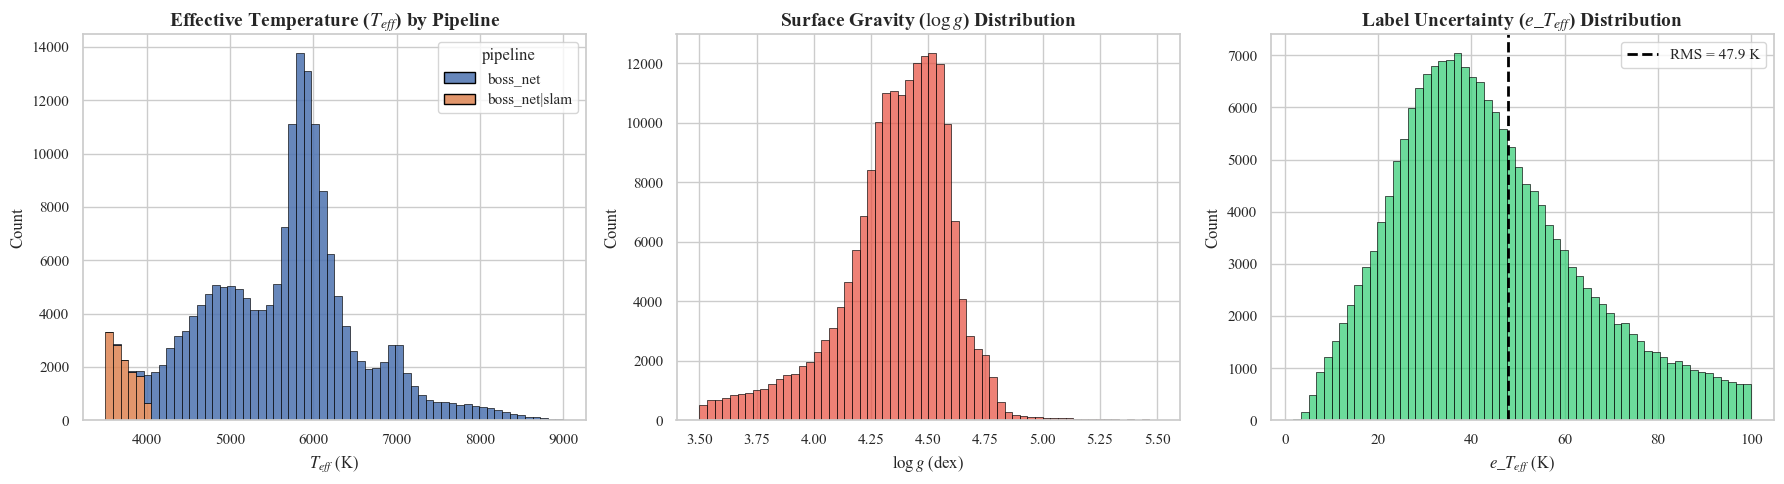

In [4]:
print("Applying Label Noise Control...")

final_df = base_filtered_df[base_filtered_df['e_teff'] <= E_TEFF_MAX].copy()

print("-" * 62)
print(f"Before e_teff cut : {len(base_filtered_df):,}")
print(f"After  e_teff <= {E_TEFF_MAX} K : {len(final_df):,} "
      f"({len(final_df)/len(base_filtered_df)*100:.1f}%)")
print("-" * 62)

# --- Label noise floor --------------------------------------------------------
sigma_label = float(np.sqrt((final_df['e_teff'] ** 2).mean()))
print(f"Label noise floor  sigma_label = RMS(e_teff) = {sigma_label:.1f} K")
print(f"  median e_teff = {final_df['e_teff'].median():.1f} K")
print("  -> no model can achieve a test RMSE below this value on this catalog.\n")

# --- Label uncertainty per Teff regime ---------------------------------------
tb = pd.cut(final_df['teff'], bins=[3500, 4000, 4500, 5000, 5500,
                                    6000, 6500, 7000, TEFF_MAX])
reg = final_df.groupby(tb, observed=True).agg(
    n=('e_teff', 'size'),
    e_teff_median=('e_teff', 'median'),
    e_teff_rms=('e_teff', lambda s: np.sqrt((s ** 2).mean())),
    snr_median=('snr', 'median'),
).round(2)
print("Label uncertainty by Teff regime:")
display(reg)

# --- Distributions ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=final_df, x='teff', hue='pipeline', bins=60, ax=axes[0],
             multiple='stack', edgecolor='black', alpha=0.85)
axes[0].set_title(r'Effective Temperature ($T_{eff}$) by Pipeline',
                  fontsize=14, fontweight='bold')
axes[0].set_xlabel(r'$T_{eff}$ (K)', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)

sns.histplot(final_df['logg'], bins=60, color='#e74c3c', ax=axes[1],
             edgecolor='black', alpha=0.7)
axes[1].set_title(r'Surface Gravity ($\log g$) Distribution',
                  fontsize=14, fontweight='bold')
axes[1].set_xlabel(r'$\log g$ (dex)', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)

sns.histplot(final_df['e_teff'], bins=60, color='#2ecc71', ax=axes[2],
             edgecolor='black', alpha=0.7)
axes[2].axvline(sigma_label, color='black', ls='--', lw=2,
                label=f'RMS = {sigma_label:.1f} K')
axes[2].set_title(r'Label Uncertainty ($e\_T_{eff}$) Distribution',
                  fontsize=14, fontweight='bold')
axes[2].set_xlabel(r'$e\_T_{eff}$ (K)', fontsize=12)
axes[2].set_ylabel('Count', fontsize=12)
axes[2].legend()

plt.tight_layout()
plt.show()

## 1.5 Exporting the Catalog
We subset the dataframe to keep only the essential columns required for the regression task and tensor matching, drastically reducing file size and I/O overhead.

The label-noise floor and the filter constants are written alongside the catalogue, in `data/catalog_meta.json`.

`logg` and `pipeline` are retained alongside the identifiers and the target so that later error analyses can be stratified by luminosity regime and by labelling pipeline.

In [5]:
# Select only the necessary columns: identifiers and the target label
essential_columns = ['catalogid', 'sdss_id', 'pipeline', 'teff', 'e_teff', 'logg', 'snr']
optimized_df = final_df[essential_columns].copy()

# Define the output file name
output_filename = 'data/sdss_catalog.csv'

print("Saving the optimized catalog...")
optimized_df.to_csv(output_filename, index=False)

# --- label-noise floor and filter constants, read by Step 2 -----------------
import json
catalog_meta = {
    'n_raw': int(len(raw_df)),
    'n_catalog': int(len(optimized_df)),
    'label_noise_floor_K': round(sigma_label, 4),
    'label_noise_floor_definition': 'RMS of e_teff over the filtered catalogue',
    'filters': {'pipeline_contains': PIPELINE_KEY, 'snr_min_exclusive': SNR_MIN,
                'logg_range': [LOGG_MIN, LOGG_MAX], 'teff_range_K': [TEFF_MIN, TEFF_MAX],
                'e_teff_max_K': E_TEFF_MAX},
    'waterfall': [{'stage': s, 'surviving': int(n)} for s, n in stages],
}
with open('data/catalog_meta.json', 'w') as f:
    json.dump(catalog_meta, f, indent=2)

print("-" * 60)
print(f"Successfully saved {len(optimized_df):,} records to '{output_filename}'")
print(f"Retained columns: {essential_columns}")
print(f"Label-noise floor {sigma_label:.1f} K written to 'data/catalog_meta.json'")
print("-" * 60)

Saving the optimized catalog...
------------------------------------------------------------
Successfully saved 188,979 records to 'data/sdss_catalog.csv'
Retained columns: ['catalogid', 'sdss_id', 'pipeline', 'teff', 'e_teff', 'logg', 'snr']
Label-noise floor 47.9 K written to 'data/catalog_meta.json'
------------------------------------------------------------
